# Tabular — Data Tidak Seimbang (imbalanced)
**Kapan dipakai:** salah satu kelas sangat jarang (misalnya penipuan 2%, penyakit langka).
Model biasa cenderung selalu menebak kelas besar, jadi akurasi tinggi tapi tidak berguna.

**Cara menyeimbangkan:**
- Oversampling (SMOTE dkk.): buat contoh buatan untuk kelas kecil.
- Undersampling: buang sebagian contoh kelas besar.
- Class weight: kesalahan pada kelas kecil diberi hukuman lebih besar.
- Geser threshold: tebak positif kalau probabilitas ≥ threshold (tidak harus 0.5).

**Metrik:** F1 kelas positif dan PR-AUC (bukan akurasi).

**Data demo:** Mammography (target `label`, kelas positif ±2%).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from catboost import CatBoostClassifier
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
from imblearn.ensemble import BalancedBaggingClassifier, RUSBoostClassifier
from imblearn.over_sampling import ADASYN, SMOTE, SVMSMOTE, BorderlineSMOTE
from imblearn.pipeline import make_pipeline
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/tabular_extra/imbalanced"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/mammography_train.csv"
TEST_CSV = f"{DATA_FOLDER}/mammography_test.csv"

TARGET = "label"
FEATURES = ["f1", "f2", "f3", "f4", "f5", "f6"]
THRESHOLD = 0.5          # tebak positif kalau probabilitas ≥ angka ini
THRESHOLDS_TO_TRY = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
missing_per_column = train.isna().sum()
print("sel kosong:", missing_per_column.sum())
train.head()

train: (8946, 8) | test: (2237, 7)
sel kosong: 0


,id,f1,f2,f3,f4,f5,f6,label
0,6743,-0.784415,-0.470195,-0.591631,-0.859553,-0.377866,-0.945723,0
1,10252,0.088415,-0.182661,-0.185897,-0.859553,-0.377866,-0.945723,0
2,585,0.104507,0.087179,1.031305,1.180548,-0.377866,1.552904,0
3,252,-0.784415,-0.470195,-0.591631,-0.859553,-0.377866,-0.945723,0
4,8753,0.148885,-0.160543,0.039510,1.015146,1.834518,1.016613,0


## EDA
Lihat seberapa jarang kelas positif, dan apakah rata-rata feature berbeda antar kelas.

In [4]:
print(train[TARGET].value_counts())
print("proporsi positif:", round(train[TARGET].mean(), 4))
train.groupby(TARGET)[FEATURES].mean()

label
0    8738
1     208
Name: count, dtype: int64
proporsi positif: 0.0233


,f1,f2,f3,f4,f5,f6
label,,,,,,
0,-0.015841,-0.003454,0.005795,-0.037271,-0.073180,-0.023802
1,0.725556,-0.119774,-0.296000,1.590891,3.031181,1.057822


## Split train / validasi
`stratify=y` penting di sini: tanpa itu, validasi bisa hampir tidak berisi kelas positif.

In [5]:
X = train[FEATURES]
y = train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

## Model
`make_pipeline` dari `imblearn`: sampler (SMOTE dkk.) hanya dipakai saat `fit`, tidak saat
`predict`, jadi data validasi/test tidak ikut diubah.
Pilih SATU `pipe`: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
pipe = make_pipeline(StandardScaler(), SMOTE(random_state=SEED),
                     LGBMClassifier(n_estimators=300, verbose=-1))
# pipe = make_pipeline(StandardScaler(), SMOTE(random_state=SEED),
#                      LogisticRegression(max_iter=2000))
# pipe = make_pipeline(StandardScaler(), BorderlineSMOTE(random_state=SEED),
#                      RandomForestClassifier(n_estimators=300, random_state=SEED))
# pipe = make_pipeline(StandardScaler(), SMOTEENN(random_state=SEED),
#                      LGBMClassifier(n_estimators=300, verbose=-1))
# pipe = make_pipeline(RandomUnderSampler(random_state=SEED),
#                      RandomForestClassifier(n_estimators=300, random_state=SEED))
# pipe = make_pipeline(StandardScaler(),
#                      LogisticRegression(class_weight="balanced", max_iter=2000))
# pipe = make_pipeline(LGBMClassifier(class_weight="balanced", verbose=-1))
# pipe = make_pipeline(XGBClassifier(scale_pos_weight=40, n_estimators=300))
# pipe = make_pipeline(BalancedRandomForestClassifier(n_estimators=300, random_state=SEED))
# pipe = make_pipeline(EasyEnsembleClassifier(n_estimators=10, random_state=SEED))
# pipe = make_pipeline(StandardScaler(), ADASYN(random_state=SEED),
#                      LGBMClassifier(n_estimators=300, verbose=-1))
# pipe = make_pipeline(StandardScaler(), SVMSMOTE(random_state=SEED),
#                      LGBMClassifier(n_estimators=300, verbose=-1))
# pipe = make_pipeline(StandardScaler(), SMOTETomek(random_state=SEED),
#                      LGBMClassifier(n_estimators=300, verbose=-1))
# pipe = make_pipeline(TomekLinks(), LGBMClassifier(n_estimators=300, verbose=-1))
# pipe = make_pipeline(CatBoostClassifier(auto_class_weights="Balanced", verbose=0,
#                                         allow_writing_files=False, random_seed=SEED))
# pipe = make_pipeline(RUSBoostClassifier(n_estimators=200, random_state=SEED))
# pipe = make_pipeline(BalancedBaggingClassifier(n_estimators=50, random_state=SEED))

pipe.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](6,)","['f1','f2','f3','f4','f5','f6']"
n_features_in_,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Evaluasi di validasi
`[:, 1]` = kolom probabilitas kelas positif.

F1 positif: 0.6234
PR-AUC    : 0.6721
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1748
           1       0.69      0.57      0.62        42

    accuracy                           0.98      1790
   macro avg       0.84      0.78      0.81      1790
weighted avg       0.98      0.98      0.98      1790



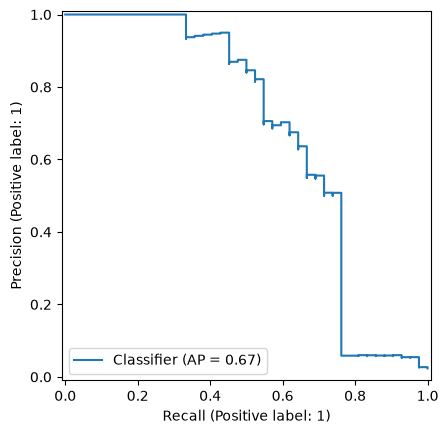

In [7]:
val_proba = pipe.predict_proba(X_val)[:, 1]
val_predictions = (val_proba >= THRESHOLD).astype(int)
print("F1 positif:", round(f1_score(y_val, val_predictions), 4))
print("PR-AUC    :", round(average_precision_score(y_val, val_proba), 4))
print(classification_report(y_val, val_predictions))
PrecisionRecallDisplay.from_predictions(y_val, val_proba)
plt.show()

## Coba beberapa threshold di validasi
Kalau ada threshold dengan F1 lebih tinggi, tulis angkanya di `THRESHOLD` (Konfigurasi).

In [8]:
for threshold in THRESHOLDS_TO_TRY:
    guess = (val_proba >= threshold).astype(int)
    print("threshold", threshold, "-> F1", round(f1_score(y_val, guess), 4))

threshold 0.1 -> F1 0.6122
threshold 0.2 -> F1 0.6364
threshold 0.3 -> F1 0.6506
threshold 0.4 -> F1 0.6582
threshold 0.5 -> F1 0.6234
threshold 0.6 -> F1 0.6216
threshold 0.7 -> F1 0.6389


## Latih ulang di semua data + submission

In [9]:
pipe.fit(X, y)
test_proba = pipe.predict_proba(test[FEATURES])[:, 1]
predictions = (test_proba >= THRESHOLD).astype(int)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission["label"].value_counts()

label
0    2185
1      52
Name: count, dtype: int64